# Proyecto 1 · Análisis exploratorio del Titanic

**Objetivo:** responder con datos qué factores se asocian a la supervivencia de los pasajeros del Titanic, usando las tres librerías de las secciones de análisis y visualización del bootcamp: **Pandas** (carga, limpieza, agregación), **Matplotlib** (control de la figura) y **Seaborn** (gráficos estadísticos).

El dataset aparece en el curso en los ejercicios de Seaborn y en la clase de regresión logística. Aquí se carga desde `seaborn.load_dataset`, así que el repositorio no redistribuye ningún archivo de datos.

**Preguntas:**

1. ¿Qué calidad tienen los datos y qué hay que limpiar?
2. ¿Influyeron el sexo y la clase del billete?
3. ¿Influyó la edad? ¿Se cumplió el "mujeres y niños primero"?
4. ¿Qué relación hay entre tarifa, clase y supervivencia?
5. ¿Viajar solo o en familia cambió algo?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
titanic = sns.load_dataset('titanic')
print(titanic.shape)
titanic.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 1. Calidad de los datos

Varias columnas son la misma información con otro formato (`survived`/`alive`, `pclass`/`class`, `embarked`/`embark_town`). Se trabaja con las originales y se miran los nulos.

In [2]:
titanic = titanic.drop(columns=['alive', 'class', 'embark_town', 'who', 'adult_male'])
nulos = titanic.isna().mean().sort_values(ascending=False) * 100
nulos[nulos > 0].round(1).to_frame('% nulos')

,% nulos
deck,77.2
age,19.9
embarked,0.2


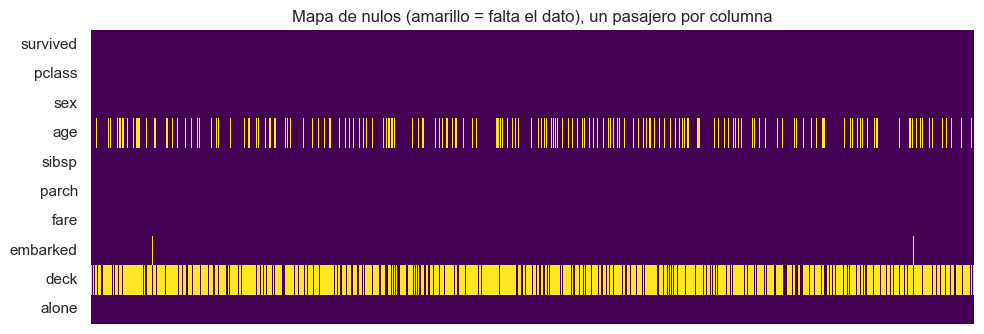

In [3]:
fig, eje = plt.subplots(figsize=(10, 3.5))
sns.heatmap(titanic.isna().T, cbar=False, cmap='viridis', ax=eje, xticklabels=False)
eje.set_title('Mapa de nulos (amarillo = falta el dato), un pasajero por columna')
plt.tight_layout()
plt.savefig('../imagenes/eda-mapa-nulos.png', dpi=110, bbox_inches='tight')
plt.show()

**Decisiones de limpieza:**

- `deck` falta en ~77% de los pasajeros: no hay base para imputar → se descarta.
- `embarked` falta en 2 filas → se rellena con el puerto más frecuente.
- `age` falta en ~20%. Rellenarla con la media global ignoraría que la edad cambia mucho según la clase. Se comprueba antes de decidir.

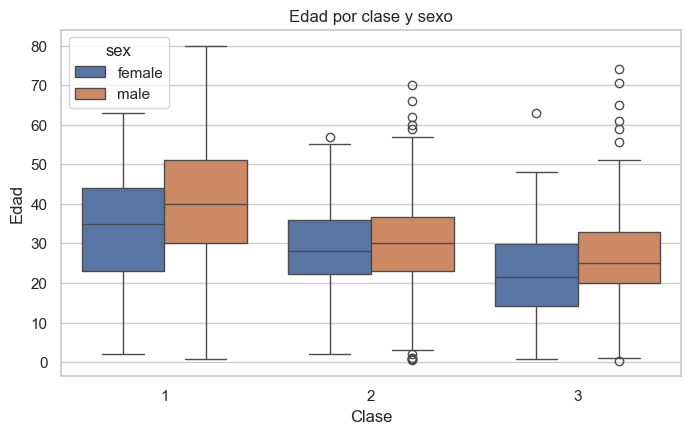

sex,female,male
pclass,,
1,35.0,40.0
2,28.0,30.0
3,21.5,25.0


In [4]:
fig, eje = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=titanic, x='pclass', y='age', hue='sex', ax=eje)
eje.set_title('Edad por clase y sexo')
eje.set_xlabel('Clase'); eje.set_ylabel('Edad')
plt.show()

titanic.groupby(['pclass', 'sex'])['age'].median().unstack().round(1)

La mediana de edad baja de forma clara de primera a tercera clase, y los hombres son algo mayores que las mujeres en todas. Por eso cada edad faltante se rellena con la **mediana de su grupo clase × sexo**, no con un valor global.

In [5]:
titanic = titanic.drop(columns='deck')
titanic['embarked'] = titanic['embarked'].fillna(titanic['embarked'].mode()[0])
titanic['edad_imputada'] = titanic['age'].isna()
titanic['age'] = titanic['age'].fillna(titanic.groupby(['pclass', 'sex'])['age'].transform('median'))
print('Nulos restantes:', int(titanic.isna().sum().sum()))

Nulos restantes: 0


## 2. Sexo y clase

Supervivencia global: 38.4%


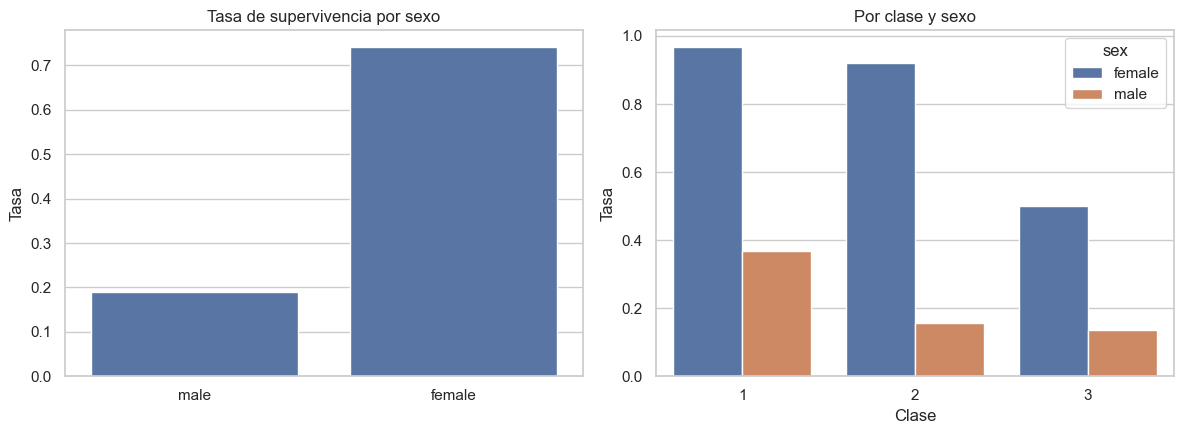

sex,female,male
pclass,,
1,0.968,0.369
2,0.921,0.157
3,0.500,0.135


In [6]:
print(f"Supervivencia global: {titanic['survived'].mean():.1%}")

fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=titanic, x='sex', y='survived', ax=izq, errorbar=None)
izq.set_title('Tasa de supervivencia por sexo'); izq.set_ylabel('Tasa'); izq.set_xlabel('')
sns.barplot(data=titanic, x='pclass', y='survived', hue='sex', ax=der, errorbar=None)
der.set_title('Por clase y sexo'); der.set_ylabel('Tasa'); der.set_xlabel('Clase')
plt.tight_layout()
plt.savefig('../imagenes/eda-sexo-clase.png', dpi=110, bbox_inches='tight')
plt.show()

titanic.pivot_table(index='pclass', columns='sex', values='survived', aggfunc='mean').round(3)

## 3. Edad

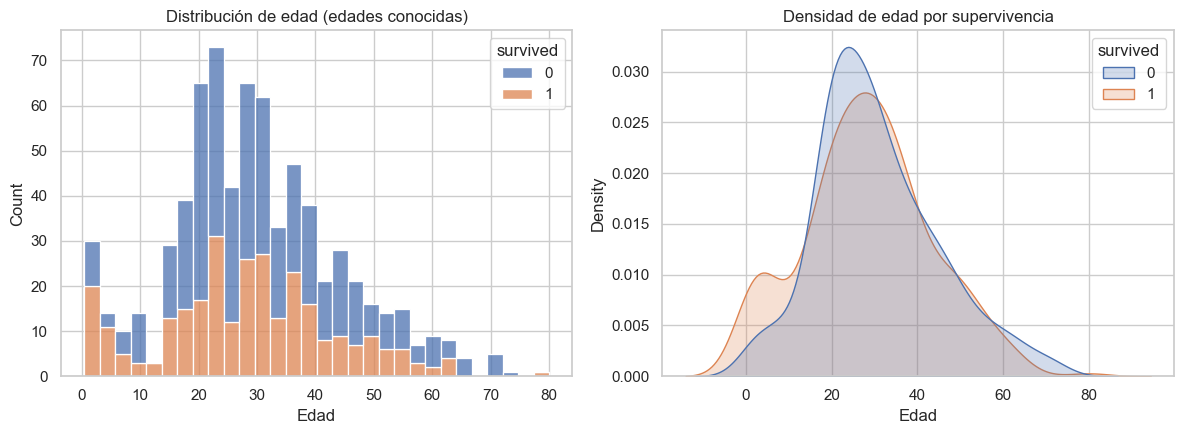

In [7]:
reales = titanic[~titanic['edad_imputada']]  # solo edades conocidas, para no distorsionar la forma
fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(data=reales, x='age', hue='survived', bins=30, multiple='stack', ax=izq)
izq.set_title('Distribución de edad (edades conocidas)'); izq.set_xlabel('Edad')
sns.kdeplot(data=reales, x='age', hue='survived', common_norm=False, fill=True, ax=der)
der.set_title('Densidad de edad por supervivencia'); der.set_xlabel('Edad')
plt.tight_layout()
plt.savefig('../imagenes/eda-edad.png', dpi=110, bbox_inches='tight')
plt.show()

In [8]:
titanic['grupo_edad'] = pd.cut(titanic['age'], bins=[0, 12, 18, 40, 60, 100],
                               labels=['Niño (0-12)', 'Adolescente (13-18)', 'Adulto (19-40)', 'Maduro (41-60)', 'Mayor (61+)'])
titanic.pivot_table(index='grupo_edad', columns='sex', values='survived', aggfunc=['mean', 'size'], observed=True).round(3)

mean          size     
sex                 female   male female male
grupo_edad                                   
Niño (0-12)          0.594  0.568     32   37
Adolescente (13-18)  0.750  0.088     36   34
Adulto (19-40)       0.758  0.166    198  404
Maduro (41-60)       0.756  0.193     45   83
Mayor (61+)          1.000  0.105      3   19

## 4. Tarifa

count    891.00
mean      32.20
std       49.69
min        0.00
25%        7.91
50%       14.45
75%       31.00
max      512.33
Name: fare, dtype: float64


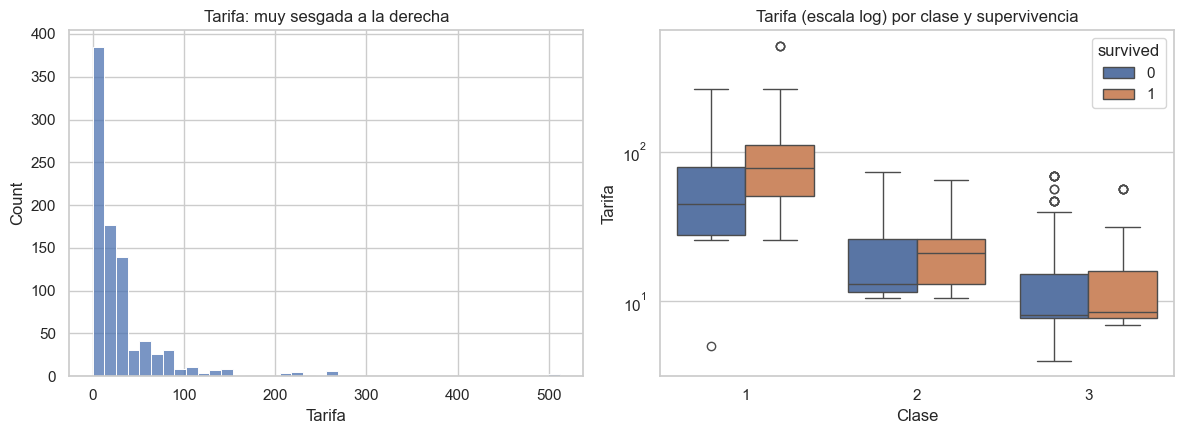

In [9]:
print(titanic['fare'].describe().round(2))
fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(titanic['fare'], bins=40, ax=izq)
izq.set_title('Tarifa: muy sesgada a la derecha'); izq.set_xlabel('Tarifa')
sns.boxplot(data=titanic, x='pclass', y='fare', hue='survived', ax=der, log_scale=True)
der.set_title('Tarifa (escala log) por clase y supervivencia'); der.set_xlabel('Clase'); der.set_ylabel('Tarifa')
plt.tight_layout()
plt.savefig('../imagenes/eda-tarifa.png', dpi=110, bbox_inches='tight')
plt.show()

## 5. Familia a bordo

`sibsp` (hermanos/cónyuge) y `parch` (padres/hijos) se combinan en un tamaño de familia.

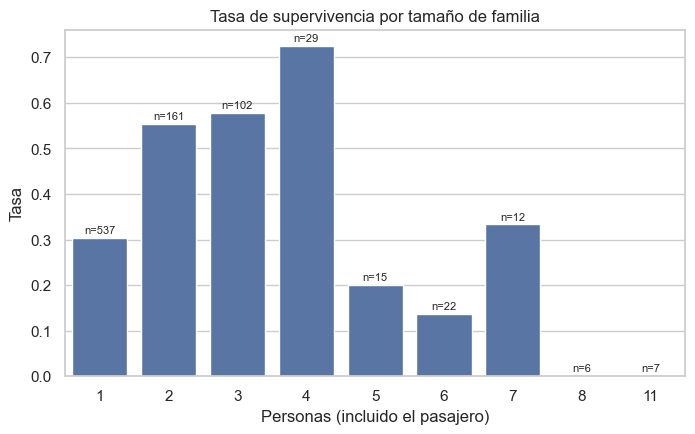

familia,1,2,3,4,5,6,7,8,11
tasa,0.304,0.553,0.578,0.724,0.2,0.136,0.333,0.0,0.0
pasajeros,537.000,161.000,102.000,29.000,15.0,22.000,12.000,6.0,7.0


In [10]:
titanic['familia'] = titanic['sibsp'] + titanic['parch'] + 1
resumen = titanic.groupby('familia')['survived'].agg(['mean', 'size']).round(3)
resumen.columns = ['tasa', 'pasajeros']

fig, eje = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=titanic, x='familia', y='survived', errorbar=None, ax=eje)
for i, (tasa, n) in enumerate(zip(resumen['tasa'], resumen['pasajeros'])):
    eje.text(i, tasa + 0.01, f'n={n}', ha='center', fontsize=8)
eje.set_title('Tasa de supervivencia por tamaño de familia'); eje.set_xlabel('Personas (incluido el pasajero)'); eje.set_ylabel('Tasa')
plt.savefig('../imagenes/eda-familia.png', dpi=110, bbox_inches='tight')
plt.show()
resumen.T

## Visión de conjunto: correlaciones

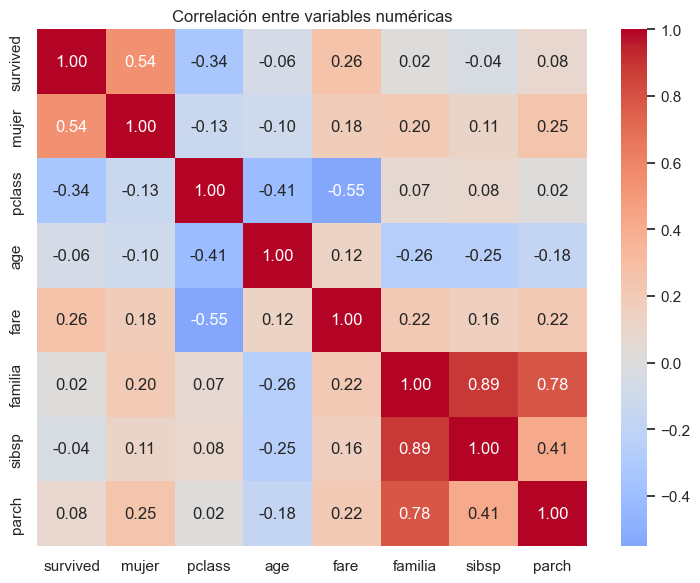

mujer      0.543
pclass    -0.338
fare       0.257
parch      0.082
age       -0.060
sibsp     -0.035
familia    0.017
Name: survived, dtype: float64

In [11]:
num = titanic.assign(mujer=(titanic['sex'] == 'female').astype(int))[
    ['survived', 'mujer', 'pclass', 'age', 'fare', 'familia', 'sibsp', 'parch']]
fig, eje = plt.subplots(figsize=(7.5, 6))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=eje)
eje.set_title('Correlación entre variables numéricas')
plt.tight_layout()
plt.savefig('../imagenes/eda-correlaciones.png', dpi=110, bbox_inches='tight')
plt.show()
num.corr()['survived'].drop('survived').sort_values(key=abs, ascending=False).round(3)

## Conclusiones

**1. Calidad de los datos.** `deck` faltaba en el 77.2% de los pasajeros y se descartó. `age` faltaba en el 19.9% y se imputó con la mediana de su grupo clase × sexo: la edad cambia mucho entre grupos, de 21.5 años (mujeres de 3ª) a 40 (hombres de 1ª). Los 2 `embarked` vacíos se rellenaron con el puerto más frecuente.

**2. El sexo es el factor dominante, y la clase el segundo.** Sobrevivió el 38.4% del pasaje, pero:

| Clase | Mujeres | Hombres |
|---|---|---|
| 1ª | 96.8% | 36.9% |
| 2ª | 92.1% | 15.7% |
| 3ª | 50.0% | 13.5% |

Una mujer de 3ª tuvo más opciones que un hombre de 1ª. Las correlaciones lo confirman: sexo 0.54 y clase −0.34 son las dos más fuertes.

**3. "Mujeres y niños primero" se cumplió, pero solo hasta los 12 años.** Los niños de 0 a 12 sobrevivieron en torno al 57%, sin diferencia entre sexos. A partir de los 13, los varones ya corrieron la suerte de los adultos: 8.8% de los adolescentes varones frente al 75% de las adolescentes. Las mujeres sobrevivieron en torno al 75% en todos los grupos de edad.

**4. La tarifa importa sobre todo a través de la clase.** Está muy sesgada (mediana 14.45, media 32.20, máximo 512.33), por eso se graficó en escala logarítmica. Dentro de 1ª clase, los supervivientes pagaron claramente más; en 3ª, apenas hay diferencia.

**5. La familia tiene un efecto no lineal que la correlación no ve.** Viajar solo (537 pasajeros) dio un 30.4% de supervivencia; en grupos de 2 a 4 personas, entre el 55% y el 72%; en familias de 5 o más, mucho menos (aunque con muy pocos casos). La correlación lineal de `familia` con la supervivencia es casi 0 (0.017) porque sube y luego baja: **una correlación cercana a 0 no significa que no haya relación**.

**Límite del análisis:** son asociaciones, no causas. Sexo, clase y tarifa están muy ligados entre sí. Para separar sus efectos haría falta un modelo, como la regresión logística que el curso aplica a este mismo dataset.